# **Multi-Agent Flight Operations Project: LangGraph Visualization**
- Names: Roxana D. and Tiffany N.

In [1]:
%pip install -q "langgraph>=1.0,<2.0"

In [11]:
from typing import TypedDict, Any, Literal
from datetime import datetime, timedelta
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from pathlib import Path
import json

# disruption state
class Disruption(TypedDict, total=False):
    flight_number: str
    scenario: str
    passenger_choice: str
    status_confirmed: bool
    flight_status: dict[str, Any]
    gate_plan: dict[str, Any]
    connection_result: dict[str, Any]
    rebooking_options: list[dict[str, Any]]
    selected_itinerary: dict[str, Any]
    connecting_plan: dict[str, Any]
    accommodation_plan: dict[str, Any]
    violations: list[str]
    no_change_msg: str
    final_confirmation: str
    resolution: str


In [16]:
# confirmed disruption activates both agents in parallel
# otherwise, will route to the the unchanged-status msg
def status_changed(state):
    return ["Gate_management", "Passenger_Connections"] if state["status_confirmed"] else "no_status_update"

# search for replacement flights if original connection is missed
# otherwise keep the passenger's existing connection
def connection_route(state):
    return "rebook" if state["connection_result"]["missed"] else "retain"

# present available flights for passenger approval
# if no options exist, offer the refund/cancel fallback
def inventory_route(state):
    return "options" if state["rebooking_options"] else "empty"

# continue only when the passenger has selected an itinerary
# an empty selection follows the declined-approval path
def approval_route(state):
    return "approved" if state["selected_itinerary"] else "declined"

# convert stored timestamps into datetime objects
# check if overnight is required depending on the time
def overnight_route(state):
    arrival = datetime.fromisoformat(state["flight_status"]["arrival"])
    departure = datetime.fromisoformat(state["selected_itinerary"]["departure"])
    return "overnight" if departure.date() > arrival.date() else "same_day"


# register each agent or processing function under its graph node name
workflow = StateGraph(Disruption)
for name, agent in {
    "central_agent": CentralAgent(),
    "Gate_management": GateManagementAgent(),
    "Passenger_Connections": PassengerConnectionsAgent(),
    "Rebooking": RebookingAgent(),
    "passenger_approval": passenger_approval,
    "Connecting_Flights": ConnectingFlightsAgent(),
    "Accommodation": AccommodationAgent(),
    "no_accommodation": no_accommodation,
    "retain_connection": retain_connection,
    "passenger_plan_ready": lambda state: {}, # synchronization marker returns no status updates
    "Feasibility_Checker": feasibility_checker,
    "final_confirmation": final_confirmation,
    "no_status_update": no_status_update,
    "refund_cancel": refund_cancel,
    "human_review": human_review,
}.items():
    workflow.add_node(name, agent)

# begin w the central agent

workflow.add_edge(START, "central_agent")

# list returned by status_changed sends execution to both listed agents (gate management and passenger connections)
workflow.add_conditional_edges("central_agent", status_changed, {
    "Gate_management": "Gate_management",
    "Passenger_Connections": "Passenger_Connections",
    "no_status_update": "no_status_update"})

# reboko missed connection or retain existing connection
workflow.add_conditional_edges("Passenger_Connections", connection_route,
                               {"rebook": "Rebooking",
                                "retain": "retain_connection"})

# request passenger approval when options exist, otherwise offer them refund/cancel
workflow.add_conditional_edges("Rebooking", inventory_route,
                               {"options": "passenger_approval",
                                "empty": "refund_cancel"})

# check the selected itinerary only after passenger approval
workflow.add_conditional_edges("passenger_approval", approval_route,
                               {"approved": "Connecting_Flights",
                                "declined": "refund_cancel"})

# propose accommodation for overnight wait or record not needed
workflow.add_conditional_edges("Connecting_Flights", overnight_route,
                               {"overnight": "Accommodation",
                                "same_day": "no_accommodation"})

# each successful passenger-planning path reaches same completion marker
for node in ["Accommodation", "no_accommodation", "retain_connection"]:
    workflow.add_edge(node, "passenger_plan_ready")


# wait for BOTH the airport plan and passenger plan; parallel agents write separate keys
workflow.add_edge(["Gate_management", "passenger_plan_ready"], "Feasibility_Checker")

# sends plan w violations to human review and plans that
# pass all check proceed to the consolidated confirmation
workflow.add_conditional_edges("Feasibility_Checker",
    lambda state: "review" if state["violations"] else "passed",
    {"review": "human_review", "passed": "final_confirmation"})

# outcomes finish
for node in ["no_status_update",
             "refund_cancel",
             "human_review",
             "final_confirmation"]:
    workflow.add_edge(node, END)
graph = workflow.compile()


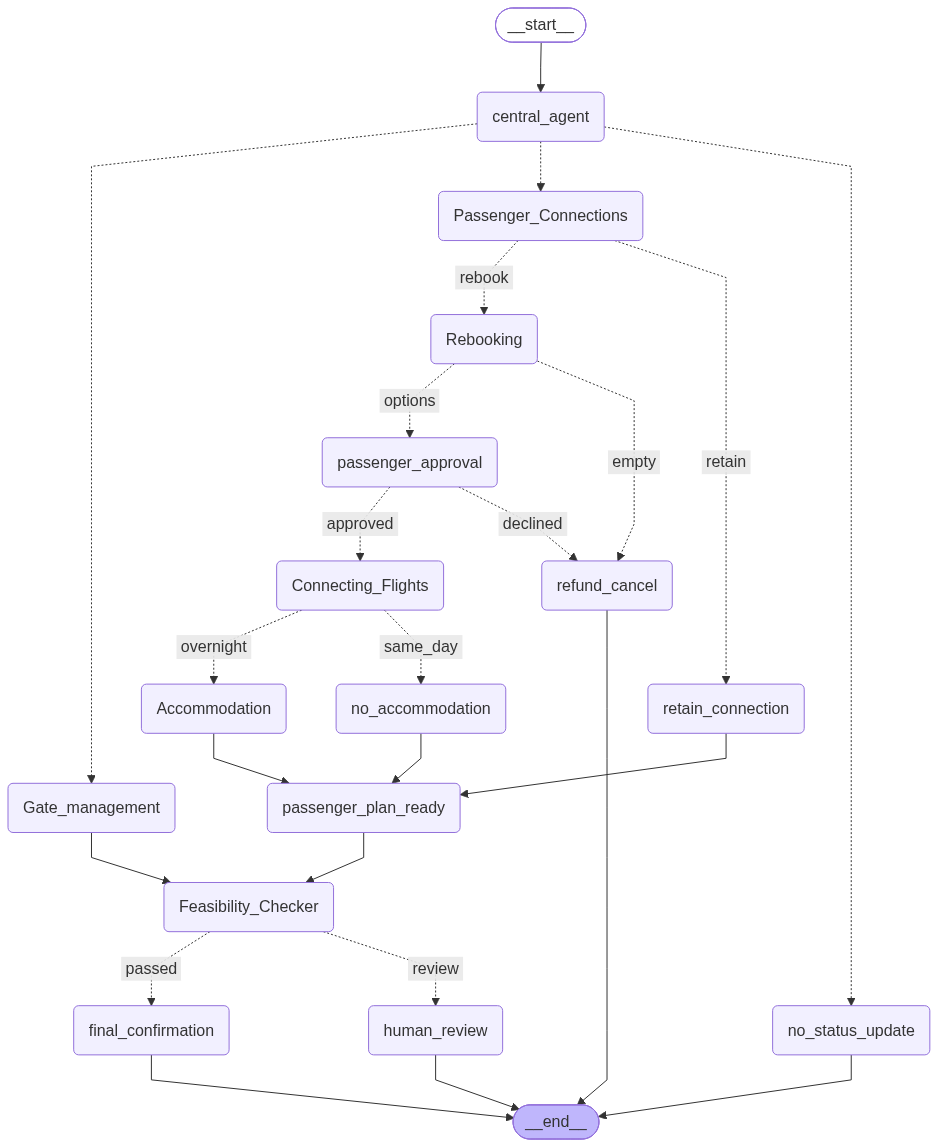

In [17]:
# The PNG comes directly from the compiled graph that is invoked below.
png_bytes = graph.get_graph().draw_mermaid_png()
display(Image(png_bytes))

## **Explanation**
### **Nodes**
- `central_agent`: verifies the reported disruption with the flight-status tool and writes the confirmed status to shared state.
- `gate_management`: proposes a compatible gate and occupied time window, including the turnaround buffer.
- `passenger_connections`: computes the connceting departure minus the updated arrival and compares it with the 45-minute minimum.
- `rebooking`: returns available onward flights when the original connection is missed.
- `passenger approval`: reads the passenger's explicit choice from the sample input. An absent or decline choice cannot create a booking.
- `connecting_flights`: checks whether the selected onward itinerary requires another connection.
- `accommodation` / `no_accommodation`: proposes a hotel and meal voucher for an overnight wait, or records that none is needed.
- `retain_connection`: keeps the original connection of sufficient time remains.
- `passenger_plan_ready`: marks completion of the passenger branch for synchronization with gate management.
- `feasibility_checker`: applies deterministic gate-overlap, aircraft-compatibility, minimum-connection-time, and seat-availability checks.
- `final_confirmation`: the Central Agent's consolidation step produces one confirmation draft aftera ll checks pass.
- `no_status_update`: returns an unchanged-status message. Repeated monitoring is describe but is not scheduled in this notebook...
- `refund_cancel`: returns the refund/cancel fallback when inventory is empty or approval is declined
- `human_review`: stops an infeasible plan for review; it does not commit conflicting actions.
- `__start__` / `__end__`: the entry and termination markers!

### **Edges & Branching**
- Start ->  Central Agent begins verification. A changed status activates both gate management and passenger connections in parallel; unchanged status routes to no_status_update -> End.
- Passenger connections -> Rebooking if slack is below the minimum; otherwise -> retain_connection.
- Rebooking -> passenger approval if options exist; otherwise -> refund/cancel. Approval -> connecting flights only when a listed option is explicitly selected; otherwise -> refund/cancel.
- Connecting flights -> accommodation if the selected departure is on a later date; otherwise -> no accommodation.
- Accommodation, no accommodation, and retained connection each finish at passenger_plan_ready. The checker waits for both gate management and passenger-plan completion. The diagram's two incoming lines represent a synchronized join, not two independent checker invocations.
- Feasibility checker -> final confirmation when there are no violations; otherwise -> human review. All terminal outcomes lead to End. Dotted arrows show conditional routes; solid arrows show fixed sequencing.
- An empty-inventory or declined-approval outcome ends the passenger branch without running the feasibility checker; the gate proposal stays uncommitted.

### **Multi-agent handoffs**
- `central_agent` -> `gate_management` and `passenger_connections`: both agents read the verified flight status written by the `Central Agent`.
- `passenger_connections` -> `rebooking`: the missed-connection result supplies the reason and final destination for recovery.
- `rebooking` -> `passenger_approval` -> `connecting_flights` -> accommodation routing: proposed options become an explicitly selected itinerary used by downstream agents.
- `gate_management` and the completed passenger branch -> `feasibility_checker` -> final_confirmation: independent outputs are merged in shared state, validated together, and consolidated by the Central Agent.